# Next-day stock price forecasting with an LSTM (Apple MLX)

An LSTM built with **Apple MLX** (it runs on the GPU of Apple silicon Macs) predicts the next day's closing price of **Safaricom** shares on the Nairobi Securities Exchange from the previous **30 days**. It is evaluated with MSE, RMSE and MAE against a naive "tomorrow = today" forecast.

**Data:** Safaricom daily prices from June 2012 to June 2019, `NSE_SCOM_Safaricom.csv` from github.com/ednamilgo/ML-Class. It is downloaded automatically if no local copy is found. Figures are written to `figures/` and the scores to `results.json`.

In [1]:
import json, time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import mlx.core as mx, mlx.nn as nn, mlx.optimizers as optim
from mlx.utils import tree_flatten, tree_map
from sklearn.metrics import mean_squared_error, mean_absolute_error
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
SEED, WINDOW = 42, 30
print("MLX", mx.__version__, "on", mx.default_device())

MLX 0.32.4 on Device(gpu, 0)


## 1. Data preparation

Only the **closing price** is used. Dates are parsed and checked to be in order. Each sample is a window of 30 closing prices and its label is the next day's close.

The data is split **by time, never shuffled**: the first 70% of target days for training, the next 15% for validation and the last 15% for testing. A window may reach back into an earlier split, but never forward, so no future information leaks into training.

In [2]:
DATA = Path("../Data Sets and Notebooks/Datasets/NSE_SCOM_Safaricom.csv")
if not DATA.exists():   # download the course file if it is missing
    import urllib.request
    DATA = Path("NSE_SCOM_Safaricom.csv")
    urllib.request.urlretrieve("https://raw.githubusercontent.com/ednamilgo/ML-Class/main/Datasets/NSE_SCOM_Safaricom.csv", DATA)
df = pd.read_csv(DATA)
df["Date"] = pd.to_datetime(df["Date"], format="%d-%m-%Y")
df = df.sort_values("Date").reset_index(drop=True)
close = df["Close"].to_numpy(dtype="float64")
print(len(df), "trading days from", df.Date.min().date(), "to", df.Date.max().date(), "| missing values:", int(df.Close.isna().sum()))
print("close price: min %.2f  max %.2f  mean %.2f KSh" % (close.min(), close.max(), close.mean()))

targets = np.arange(WINDOW, len(close))              # index of the day being predicted
n = len(targets); n_tr, n_va = int(n * 0.70), int(n * 0.15)
split = {"train": targets[:n_tr], "val": targets[n_tr:n_tr + n_va], "test": targets[n_tr + n_va:]}
for k, v in split.items():
    print(f"{k:5s} {len(v):4d} samples  {df.Date[v[0]].date()} to {df.Date[v[-1]].date()}  price {close[v].min():.2f}-{close[v].max():.2f}")

1753 trading days from 2012-06-11 to 2019-06-14 | missing values: 0
close price: min 3.40  max 32.75  mean 16.78 KSh
train 1206 samples  2012-07-23 to 2017-05-16  price 3.75-21.25
val    258 samples  2017-05-17 to 2018-05-31  price 20.00-32.75
test   259 samples  2018-06-04 to 2019-06-14  price 21.30-30.00


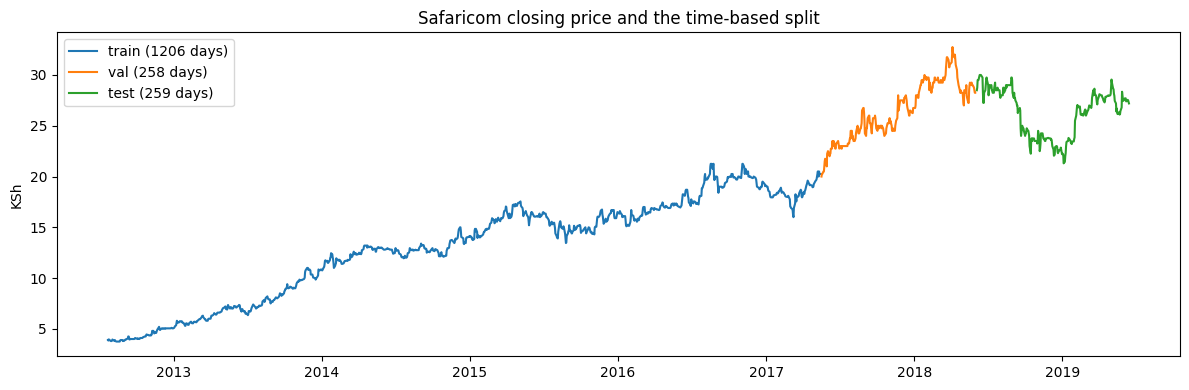

In [3]:
fig, ax = plt.subplots(figsize=(12, 4))
colors = {"train": "tab:blue", "val": "tab:orange", "test": "tab:green"}
for k, v in split.items():
    ax.plot(df.Date[v], close[v], color=colors[k], label=f"{k} ({len(v)} days)")
ax.set_title("Safaricom closing price and the time-based split"); ax.set_ylabel("KSh"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "price_split.png", dpi=150); plt.show()

**Two ways of scaling** the windows for the LSTM:

- **Global min-max** (the course method): every price is scaled to 0–1 using the minimum and maximum of the **training** prices. Test prices higher than any training price fall above 1.
- **Window-relative:** each window is divided by its own last price, so the inputs are ratios close to 1 and the label is the next price divided by today's price. The model then learns daily **relative changes**, which look alike whether the share costs KSh 5 or KSh 30.

In [4]:
lo, hi = close[split["train"]].min(), close[split["train"]].max()
def make(idx, mode):
    X = np.stack([close[t - WINDOW:t] for t in idx]); y = close[idx]; last = X[:, -1]
    if mode == "minmax":
        Xs, ys = (X - lo) / (hi - lo), (y - lo) / (hi - lo)
    else:
        Xs, ys = X / last[:, None] - 1.0, y / last - 1.0
    return Xs[..., None].astype("float32"), ys.astype("float32"), last
def unscale(pred, last, mode):
    return pred * (hi - lo) + lo if mode == "minmax" else (pred + 1.0) * last
print("training price range used for min-max: %.2f to %.2f KSh" % (lo, hi))

training price range used for min-max: 3.75 to 21.25 KSh


## 2. Models

- **Naive baseline:** tomorrow's price = today's price. Any useful model has to beat this.
- **LSTM:** one or two LSTM layers over the 30-day window, optional dropout, then a Dense layer that outputs the next value. It is trained with Adam (learning rate 0.001, batches of 32) on the mean squared error, with **early stopping** on the validation loss (patience 15, best weights kept, at most 150 epochs).

In [5]:
class LSTMNet(nn.Module):
    def __init__(self, hidden=32, layers=1, dropout=0.0):
        super().__init__()
        self.lstms = [nn.LSTM(1 if i == 0 else hidden, hidden) for i in range(layers)]
        self.drop = nn.Dropout(dropout) if dropout else None
        self.out = nn.Linear(hidden, 1)
    def __call__(self, x):
        for l in self.lstms:
            x, _ = l(x)
            if self.drop is not None: x = self.drop(x)
        return self.out(x[:, -1, :]).squeeze(-1)

def n_params(m): return sum(v.size for _, v in tree_flatten(m.trainable_parameters()))
def mse_loss(m, x, y): return mx.mean((m(x) - y) ** 2)

def fit(cfg, epochs=150, patience=15, bs=32):
    mx.random.seed(SEED); rng = np.random.default_rng(SEED)
    Xtr, ytr, _ = make(split["train"], cfg["mode"]); Xva, yva, _ = make(split["val"], cfg["mode"])
    model = LSTMNet(cfg["hidden"], cfg["layers"], cfg["dropout"]); mx.eval(model.parameters())
    opt = optim.Adam(learning_rate=1e-3); step = nn.value_and_grad(model, mse_loss)
    best, best_w, wait, hist = np.inf, None, 0, {"train": [], "val": []}
    for ep in range(epochs):
        model.train(); order = rng.permutation(len(Xtr)); tl = 0.0
        for i in range(0, len(order), bs):
            b = order[i:i + bs]
            loss, g = step(model, mx.array(Xtr[b]), mx.array(ytr[b])); opt.update(model, g)
            mx.eval(model.parameters(), opt.state); tl += loss.item() * len(b)
        model.eval(); vl = mse_loss(model, mx.array(Xva), mx.array(yva)).item()
        hist["train"].append(tl / len(order)); hist["val"].append(vl)
        if vl < best - 1e-9: best, wait, best_w = vl, 0, tree_map(lambda a: mx.array(a), model.parameters())
        else:
            wait += 1
            if wait >= patience: break
    model.update(best_w); mx.eval(model.parameters()); model.eval()
    return model, hist, int(np.argmin(hist["val"])) + 1

def predict(model, idx, mode):
    X, _, last = make(idx, mode)
    return unscale(np.array(model(mx.array(X))), last, mode)

def scores(idx, pred):
    a = close[idx]
    return {"MSE": float(mean_squared_error(a, pred)), "RMSE": float(np.sqrt(mean_squared_error(a, pred))),
            "MAE": float(mean_absolute_error(a, pred)),
            "direction": float(np.mean(np.sign(pred - close[idx - 1]) == np.sign(a - close[idx - 1])))}

## 3. Hyperparameter tuning

Each setting is judged on the **validation** days only (MSE, RMSE and MAE in KSh). "Direction" is the share of days where the model got the up or down move right (days with no change count as wrong).

In [6]:
configs = {
    "Min-max, 1 x 50 (course style)": {"mode": "minmax", "hidden": 50, "layers": 1, "dropout": 0.0},
    "Min-max, 2 x 50 + dropout 0.2 (course model)": {"mode": "minmax", "hidden": 50, "layers": 2, "dropout": 0.2},
    "Window-relative, 1 x 32": {"mode": "relative", "hidden": 32, "layers": 1, "dropout": 0.0},
    "Window-relative, 1 x 64": {"mode": "relative", "hidden": 64, "layers": 1, "dropout": 0.0},
    "Window-relative, 2 x 50 + dropout 0.2": {"mode": "relative", "hidden": 50, "layers": 2, "dropout": 0.2},
}
val_idx = split["val"]
tuning = {"Naive (tomorrow = today)": {**scores(val_idx, close[val_idx - 1]), "params": 0, "best_epoch": 0, "seconds": 0}}
models, histories = {}, {}
for name, cfg in configs.items():
    t0 = time.time()
    m, h, be = fit(cfg)
    tuning[name] = {**scores(val_idx, predict(m, val_idx, cfg["mode"])), "params": int(n_params(m)), "best_epoch": be, "seconds": round(time.time() - t0)}
    models[name], histories[name] = m, h
for k, v in tuning.items():
    print(f"{k:46s} RMSE {v['RMSE']:.4f}  MAE {v['MAE']:.4f}  MSE {v['MSE']:.4f}  dir {v['direction']:.3f}  epoch {v['best_epoch']}  {v['seconds']}s")

Naive (tomorrow = today)                       RMSE 0.4176  MAE 0.2946  MSE 0.1744  dir 0.306  epoch 0  0s
Min-max, 1 x 50 (course style)                 RMSE 0.7745  MAE 0.6056  MSE 0.5998  dir 0.364  epoch 20  6s
Min-max, 2 x 50 + dropout 0.2 (course model)   RMSE 1.1470  MAE 0.8888  MSE 1.3156  dir 0.349  epoch 26  13s
Window-relative, 1 x 32                        RMSE 0.4139  MAE 0.3052  MSE 0.1713  dir 0.407  epoch 23  6s
Window-relative, 1 x 64                        RMSE 0.4133  MAE 0.3028  MSE 0.1708  dir 0.422  epoch 21  5s
Window-relative, 2 x 50 + dropout 0.2          RMSE 0.4125  MAE 0.3022  MSE 0.1702  dir 0.415  epoch 95  34s


best LSTM on validation: Window-relative, 2 x 50 + dropout 0.2


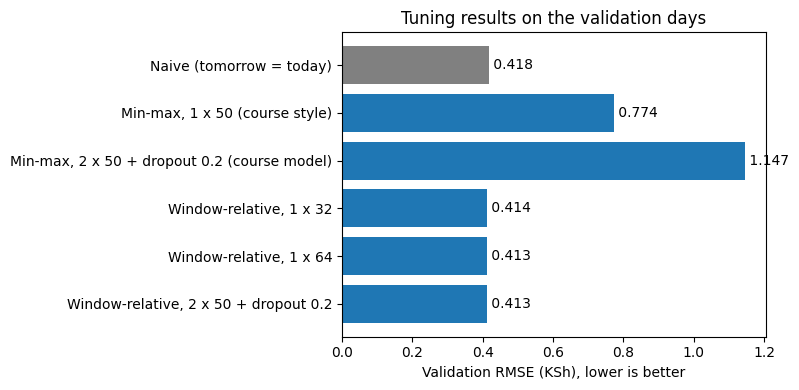

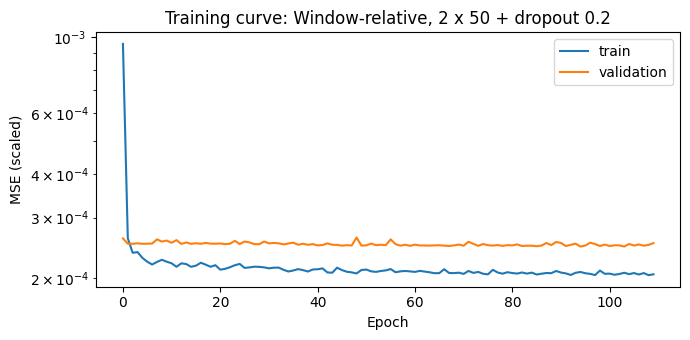

In [7]:
best_name = min(configs, key=lambda k: tuning[k]["RMSE"])
print("best LSTM on validation:", best_name)
fig, ax = plt.subplots(figsize=(8, 4))
names = list(tuning); vals = [tuning[k]["RMSE"] for k in names]
ax.barh(names, vals, color=["grey"] + ["tab:blue"] * (len(names) - 1)); ax.invert_yaxis()
ax.set_xlabel("Validation RMSE (KSh), lower is better"); ax.set_title("Tuning results on the validation days")
for i, v in enumerate(vals): ax.text(v, i, f" {v:.3f}", va="center")
plt.tight_layout(); plt.savefig(FIG / "tuning_rmse.png", dpi=150); plt.show()
h = histories[best_name]
fig, ax = plt.subplots(figsize=(7, 3.5)); ax.plot(h["train"], label="train"); ax.plot(h["val"], label="validation")
ax.set_yscale("log"); ax.set_xlabel("Epoch"); ax.set_ylabel("MSE (scaled)"); ax.set_title(f"Training curve: {best_name}"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "training_curve.png", dpi=150); plt.show()

## 4. Evaluation on the test days

The chosen LSTM and the course-style model are scored once on the **test** days and compared with the naive baseline.

Naive (tomorrow = today)                                       MSE 0.1822  RMSE 0.4269  MAE 0.2813  direction 0.228
LSTM: Min-max, 2 x 50 + dropout 0.2 (course model)             MSE 0.9962  RMSE 0.9981  MAE 0.7911  direction 0.409
LSTM: Window-relative, 2 x 50 + dropout 0.2                    MSE 0.1781  RMSE 0.4220  MAE 0.2859  direction 0.432


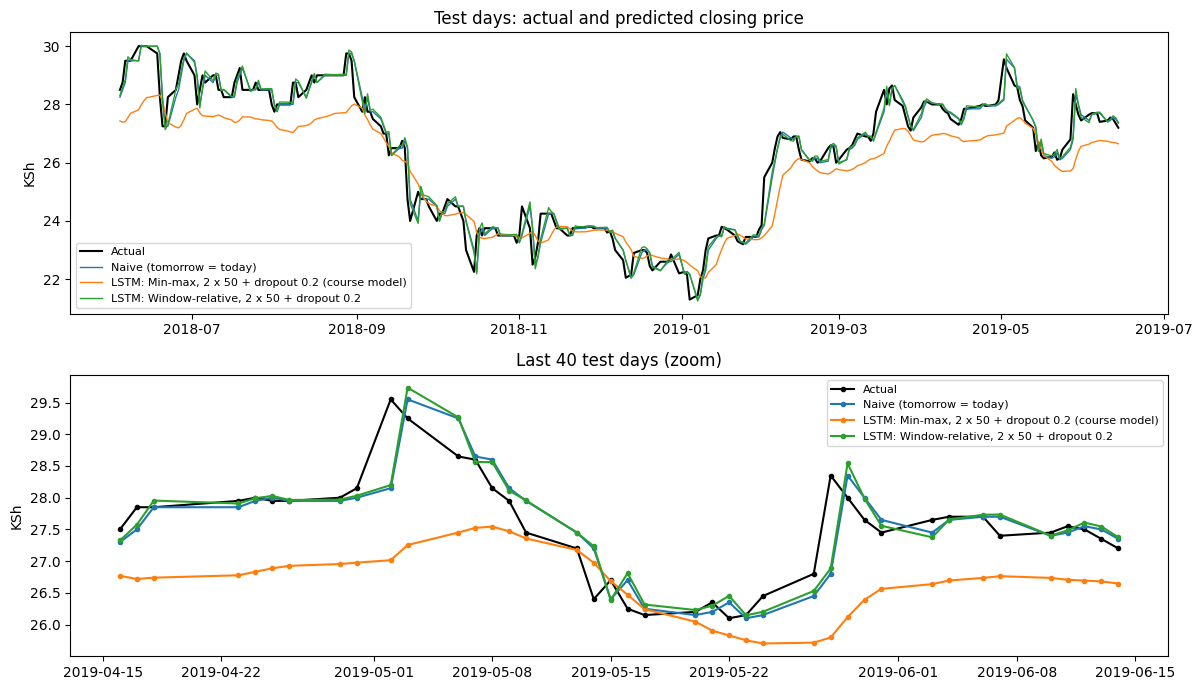

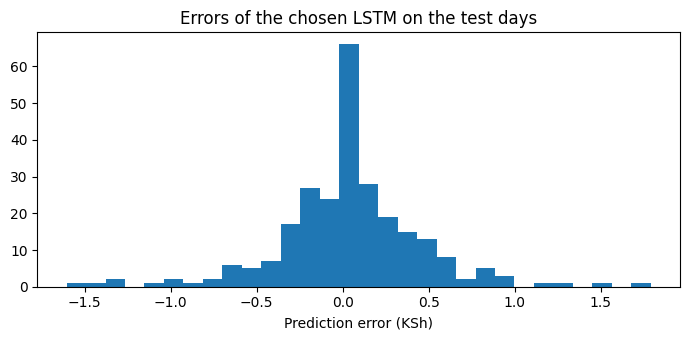

In [8]:
test_idx = split["test"]
course_name = "Min-max, 2 x 50 + dropout 0.2 (course model)"
preds = {"Naive (tomorrow = today)": close[test_idx - 1],
         f"LSTM: {course_name}": predict(models[course_name], test_idx, configs[course_name]["mode"]),
         f"LSTM: {best_name}": predict(models[best_name], test_idx, configs[best_name]["mode"])}
test_scores = {k: scores(test_idx, p) for k, p in preds.items()}
for k, v in test_scores.items():
    print(f"{k:62s} MSE {v['MSE']:.4f}  RMSE {v['RMSE']:.4f}  MAE {v['MAE']:.4f}  direction {v['direction']:.3f}")
fig, axes = plt.subplots(2, 1, figsize=(12, 7))
d = df.Date[test_idx]
axes[0].plot(d, close[test_idx], color="black", lw=1.5, label="Actual")
for k, p in preds.items(): axes[0].plot(d, p, lw=1, label=k)
axes[0].set_title("Test days: actual and predicted closing price"); axes[0].set_ylabel("KSh"); axes[0].legend(fontsize=8)
z = slice(-40, None)
axes[1].plot(d[z], close[test_idx][z], color="black", marker="o", ms=3, label="Actual")
for k, p in preds.items(): axes[1].plot(d[z], p[z], marker=".", label=k)
axes[1].set_title("Last 40 test days (zoom)"); axes[1].set_ylabel("KSh"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "test_predictions.png", dpi=150); plt.show()
err = preds[f"LSTM: {best_name}"] - close[test_idx]
fig, ax = plt.subplots(figsize=(7, 3.5)); ax.hist(err, bins=30, color="tab:blue")
ax.set_xlabel("Prediction error (KSh)"); ax.set_title("Errors of the chosen LSTM on the test days")
plt.tight_layout(); plt.savefig(FIG / "test_errors.png", dpi=150); plt.show()

In [9]:
Path("results.json").write_text(json.dumps({
    "n_days": len(df), "dates": [str(df.Date.min().date()), str(df.Date.max().date())],
    "split": {k: {"n": int(len(v)), "start": str(df.Date[v[0]].date()), "end": str(df.Date[v[-1]].date()),
                  "min": float(close[v].min()), "max": float(close[v].max())} for k, v in split.items()},
    "train_range": [float(lo), float(hi)], "window": WINDOW, "tuning": tuning, "best": best_name,
    "test": test_scores, "mlx": mx.__version__}, indent=1))
print("saved results.json")

saved results.json
